# **Capital Bikeshare Project**

---



# Capital Bikeshare Data Analysis

## 1. Project Overview

This collaborative data analysis project explores bike-sharing usage patterns using trip records, rider information, station data, and weather observations.

The analysis uses SQL and SQLite to investigate ridership trends, customer behavior, peak demand periods, station utilization, trip duration, and the relationship between weather conditions and bike-sharing activity.

The goal is to transform raw data into actionable insights that can support operational planning, improve bike availability, and enhance the customer experience.

**Tools & Technologies:** Python, SQL, SQLite, Pandas, Jupyter Notebook.

**Project Type:** Collaborative Data Analysis Project.

## 2. Project Objectives

The main objective of this project is to understand bike-sharing usage patterns and identify opportunities for operational improvement.

The analysis addresses the following business questions:

- **Demand Patterns:** When are bike-sharing trips most frequent across hours of the day and days of the week?
- **Rider Behavior:** How do registered members and casual riders differ in trip frequency and duration?
- **Bike Usage:** How many trips are recorded for each bike type, and how are bike types used by different rider groups?
- **Station Utilization:** Which stations have the highest departure activity, and which routes are most frequently traveled?
- **Trip Characteristics:** How long do trips typically last, and how frequently do riders return bikes to their starting stations?
- **Weather Impact:** How does average daily ridership vary across recorded weather conditions?
- **Data Quality:** Are there invalid timestamps, negative trip durations, or unusually long trips that could affect the analysis?

The findings are intended to support data-driven decisions about bike distribution, service planning, and customer engagement.

## 3. Data Collection & Database Setup

The project uses the **Capital Bikeshare dataset**, obtained from Kaggle.

The data is organized into four tables:

- `daily_rent_detail`: Individual bike trip records, including start and end timestamps, station IDs, bike type, and rider category.
- `station_list`: Station identifiers and station names.
- `weather`: Daily weather observations, including weather conditions and precipitation.
- `usage_frequency`: Additional usage-related data provided in the dataset.

### Database Preparation

SQLite was used to create a relational database and execute SQL queries.

Python and Pandas were used to load the source CSV files into the database. The large trip-detail file was processed in chunks of 50,000 rows to reduce memory usage during ingestion.

The resulting database provides a structured foundation for exploratory data analysis and joins across trip, station, and weather information.

**Data Source:** [Capital Bikeshare Dataset on Kaggle](https://www.kaggle.com/datasets/taweilo/capital-bikeshare-dataset-202005202408)

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("taweilo/capital-bikeshare-dataset-202005202408")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'capital-bikeshare-dataset-202005202408' dataset.
Path to dataset files: /kaggle/input/capital-bikeshare-dataset-202005202408


In [2]:
# Creating database
import pandas as pd
import sqlite3
import os

db = sqlite3.connect("city_bike_share.db")

In [3]:
file_path = os.path.join(path, "station_list.csv")

df = pd.read_csv(file_path)
df.to_sql("station_list", db, if_exists="replace", index=False)

del df

file_path = os.path.join(path, "weather.csv")

df = pd.read_csv(file_path)
df.to_sql("weather", db, if_exists="replace", index=False)

del df

file_path = os.path.join(path, "usage_frequency.csv")

df = pd.read_csv(file_path)
df.to_sql("usage_frequency", db, if_exists="replace", index=False)

del df


In [4]:
file_path = os.path.join(path, "daily_rent_detail.csv")

first_chunk = True

for chunk in pd.read_csv(file_path, chunksize=50000, low_memory=False):
    chunk.to_sql(
        "daily_rent_detail",
        db,
        if_exists="replace" if first_chunk else "append",
        index=False
    )
    first_chunk = False
    del chunk

## 4. Exploratory Data Analysis (EDA)

This section explores the dataset using SQL queries to understand its structure, validate data quality, and identify patterns in bike-sharing usage.

The analysis is organized into data exploration, data quality checks, demand patterns, rider behavior, station utilization, and weather-related trends.

In [5]:
# Creating function for running SQL queries
def run(query):
    return pd.read_sql_query(query, db)

In [6]:
# Identifying the tables
run("""SELECT name
FROM sqlite_master
WHERE type = 'table' """)

,name
0,station_list
1,weather
2,usage_frequency
3,daily_rent_detail


In [7]:
# Identifying the number of rows for each table
run("""
SELECT 'station_list' AS table_name, COUNT(*) AS rows
FROM station_list

UNION ALL

SELECT 'weather', COUNT(*)
FROM weather

UNION ALL

SELECT 'usage_frequency', COUNT(*)
FROM usage_frequency

UNION ALL

SELECT 'daily_rent_detail', COUNT(*)
FROM daily_rent_detail;
""")

,table_name,rows
0,station_list,916
1,weather,1584
2,usage_frequency,873318
3,daily_rent_detail,16086672


In [8]:
# "Station_list" Table data sample
run("SELECT * FROM station_list LIMIT 5")

,station_id,station_name
0,30200,9th St & Pennsylvania Ave NW
1,30201,9th & G St NW
2,31000,Eads St & 15th St S
3,31001,18th St & S Eads St
4,31002,Crystal Dr & 20th St S


In [9]:
# "Weather" Table data sample
run("SELECT * FROM weather LIMIT 5")

,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,"Washington,DC,USA",2020-05-01,18.8,11.6,14.9,18.8,11.6,14.9,8.9,69.6,...,9.5,6,None,2020-05-01T06:09:41,2020-05-01T20:01:16,0.30,"Rain, Partially cloudy",Partly cloudy throughout the day with rain cle...,rain,"KDCA,72405013743,72403793728,F0198,KADW,KDAA,7..."
1,"Washington,DC,USA",2020-05-02,22.1,11.1,16.3,22.1,11.1,16.3,6.4,54.0,...,14.0,9,None,2020-05-02T06:08:30,2020-05-02T20:02:13,0.33,Partially cloudy,Partly cloudy throughout the day.,partly-cloudy-day,"KDCA,72405013743,72403793728,F0198,KGAI,KADW,K..."
2,"Washington,DC,USA",2020-05-03,24.9,15.6,18.6,24.9,15.6,18.6,13.4,72.5,...,5.7,4,None,2020-05-03T06:07:21,2020-05-03T20:03:11,0.37,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"KDCA,72405013743,72403793728,F0198,KADW,KDAA,7..."
3,"Washington,DC,USA",2020-05-04,23.8,14.3,19.2,23.8,14.3,19.2,7.8,53.8,...,13.3,8,None,2020-05-04T06:06:12,2020-05-04T20:04:08,0.40,"Rain, Partially cloudy",Clearing in the afternoon with early morning r...,rain,"KDCA,72405013743,72403793728,F0198,KADW,KDAA,7..."
4,"Washington,DC,USA",2020-05-05,14.3,9.3,12.3,14.3,8.0,12.1,3.3,55.6,...,5.0,2,None,2020-05-05T06:05:06,2020-05-05T20:05:05,0.44,"Rain, Partially cloudy",Partly cloudy throughout the day with late aft...,rain,"KIAD,KDCA,72405013743,72403793728,72403093738,..."


In [10]:
# "Usge_Frequency" Table data sample
run("SELECT * FROM usage_frequency LIMIT 5")

,date,station_name,pickup_counts,dropoff_counts
0,2020-05-01,10th & E St NW,11,7.0
1,2020-05-01,10th & Florida Ave NW,8,8.0
2,2020-05-01,10th & G St NW,3,2.0
3,2020-05-01,10th & K St NW,12,15.0
4,2020-05-01,10th & Monroe St NE,5,6.0


In [11]:
# "Daily_Rent_Detail" Table data sample
run("SELECT * FROM daily_rent_detail LIMIT 5")

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29,2020-05-31 18:25:22,Anacostia Library,31804,11th & H St NE,31614.0,38.865784,-76.978400,38.899983,-76.991383,casual
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04,2020-05-09 15:06:33,10th & E St NW,31256,21st St & Constitution Ave NW,31261.0,38.895914,-77.026064,38.892459,-77.046567,member
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19,2020-05-24 17:43:51,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268.0,38.934267,-77.057979,38.916787,-77.028139,member
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52,2020-05-27 15:47:13,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119.0,38.934267,-77.057979,38.921074,-77.031887,casual
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03,2020-05-31 14:30:30,Georgia Ave & Morton St NW,31419,17th & K St NW,31213.0,38.932128,-77.023500,38.902760,-77.038630,casual


In [12]:
# "Usge_Frequency" Table columns information
run("""PRAGMA table_info(usage_frequency)""")

,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,station_name,TEXT,0,None,0
2,2,pickup_counts,INTEGER,0,None,0
3,3,dropoff_counts,REAL,0,None,0


In [13]:
# "Daily_Rent_Detail" Table columns information
run("""PRAGMA table_info(daily_rent_detail)""")

,cid,name,type,notnull,dflt_value,pk
0,0,ride_id,TEXT,0,None,0
1,1,rideable_type,TEXT,0,None,0
2,2,started_at,TEXT,0,None,0
3,3,ended_at,TEXT,0,None,0
4,4,start_station_name,TEXT,0,None,0
5,5,start_station_id,INTEGER,0,None,0
6,6,end_station_name,TEXT,0,None,0
7,7,end_station_id,REAL,0,None,0
8,8,start_lat,REAL,0,None,0
9,9,start_lng,REAL,0,None,0


In [14]:
# "Station_List" Table columns information
run("""PRAGMA table_info(station_list)""")

,cid,name,type,notnull,dflt_value,pk
0,0,station_id,INTEGER,0,None,0
1,1,station_name,TEXT,0,None,0


In [15]:
# "Weather" Table columns information
run("""PRAGMA table_info(weather)""")

,cid,name,type,notnull,dflt_value,pk
0,0,name,TEXT,0,None,0
1,1,datetime,TEXT,0,None,0
2,2,tempmax,REAL,0,None,0
3,3,tempmin,REAL,0,None,0
4,4,temp,REAL,0,None,0
5,5,feelslikemax,REAL,0,None,0
6,6,feelslikemin,REAL,0,None,0
7,7,feelslike,REAL,0,None,0
8,8,dew,REAL,0,None,0
9,9,humidity,REAL,0,None,0


## Member VS casual riders: number of trips and average duration?

,member_casual,number_of_trips,avg_trip_duration_in_minutes
0,casual,6289745,39.281819
1,member,9786187,14.469823


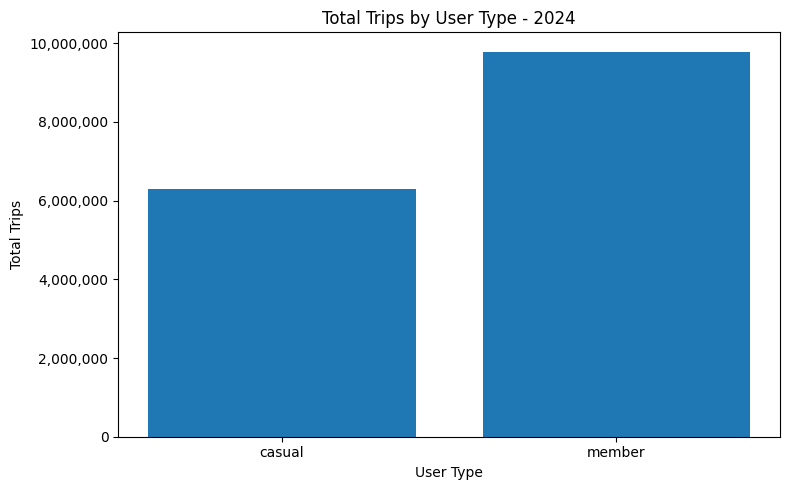

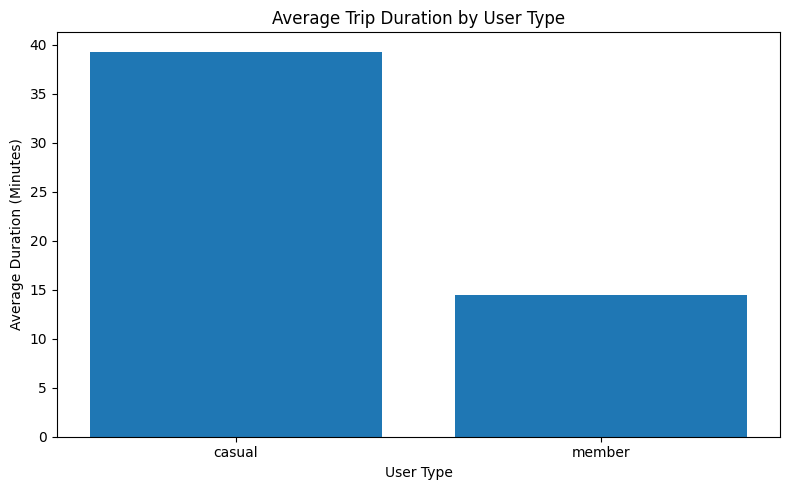

In [16]:
df_users = run("""SELECT member_casual,
COUNT(*) AS number_of_trips,
AVG((julianday(ended_at) - julianday(started_at)) * 24 * 60) AS avg_trip_duration_in_minutes
FROM daily_rent_detail
WHERE ended_at > started_at
GROUP BY member_casual""")

display(df_users)

# Graph 1: Number of Trips by User Type

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(8, 5))
plt.bar(df_users["member_casual"], df_users["number_of_trips"])

plt.title("Total Trips by User Type - 2024")
plt.xlabel("User Type")
plt.ylabel("Total Trips")

# Display full numbers with thousands separators
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()


# Graph 2: Average Trip Duration by User Type
plt.figure(figsize=(8, 5))
plt.bar(df_users["member_casual"], df_users["avg_trip_duration_in_minutes"])

plt.title("Average Trip Duration by User Type")
plt.xlabel("User Type")
plt.ylabel("Average Duration (Minutes)")

plt.tight_layout()
plt.show()

## Number of trips for each bike type?

,rideable_type,total_trips
0,classic_bike,9613205
1,electric_bike,4614172
2,docked_bike,1848555


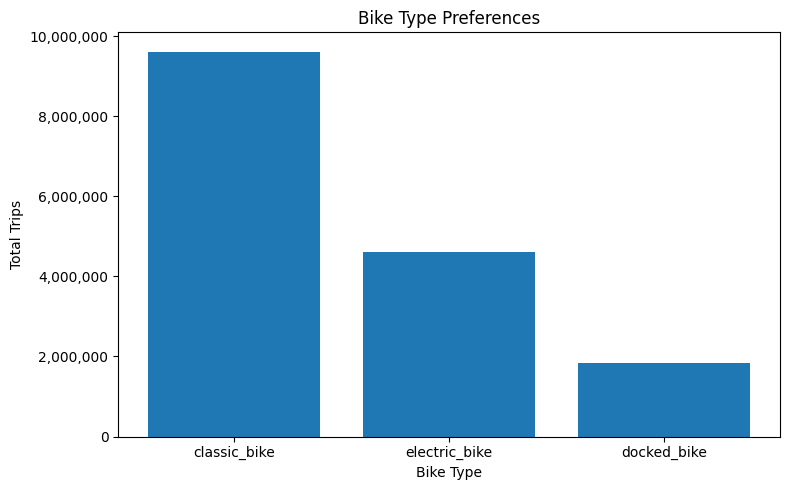

In [17]:
df_bike = run("""SELECT rideable_type,
COUNT(*) AS total_trips
FROM daily_rent_detail
WHERE ended_at > started_at
GROUP BY rideable_type
ORDER BY total_trips DESC""")

display(df_bike)

# Creating graph for total trips for each bike type

plt.figure(figsize=(8, 5))
plt.bar(df_bike["rideable_type"], df_bike["total_trips"])

plt.title("Bike Type Preferences")
plt.xlabel("Bike Type")
plt.ylabel("Total Trips")

# Display full numbers with thousands separators
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

## How many bikes of each type (Classic / Electric/ Docked) does the fleet have, and how many riders are Members vs Casual?


In [18]:
run("""SELECT rideable_type,
    member_casual,
    COUNT(*) AS number_of_rides
    FROM daily_rent_detail
    GROUP BY rideable_type, member_casual
    ORDER BY rideable_type, member_casual""")

,rideable_type,member_casual,number_of_rides
0,classic_bike,casual,3381403
1,classic_bike,member,6232736
2,docked_bike,casual,1159599
3,docked_bike,member,696186
4,electric_bike,casual,1752513
5,electric_bike,member,2864235


## Total number of trips, average duration; then the same broken down by month of 2024.

,total_trips,avg_trip_duration,month
0,238699,14.778978,01
1,318545,14.625152,02
2,436708,18.054923,03
3,489967,17.063239,04
4,515308,17.415000,05
5,584357,18.176259,06
6,589443,17.576907,07
7,614564,16.621988,08


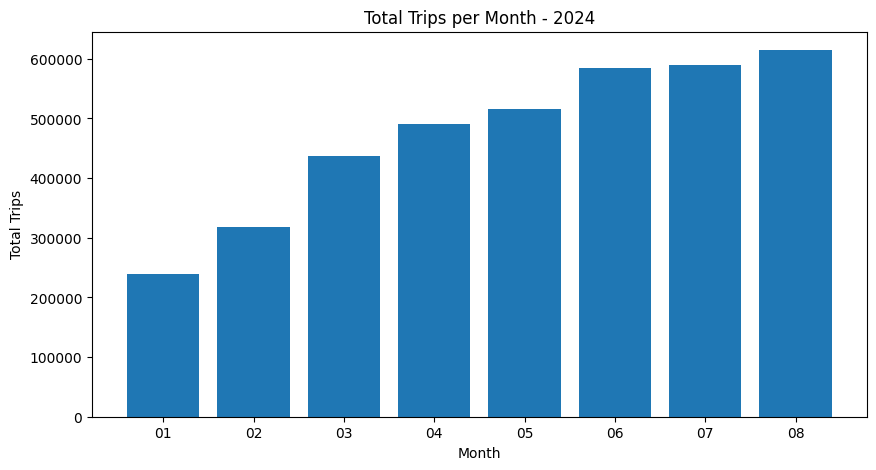

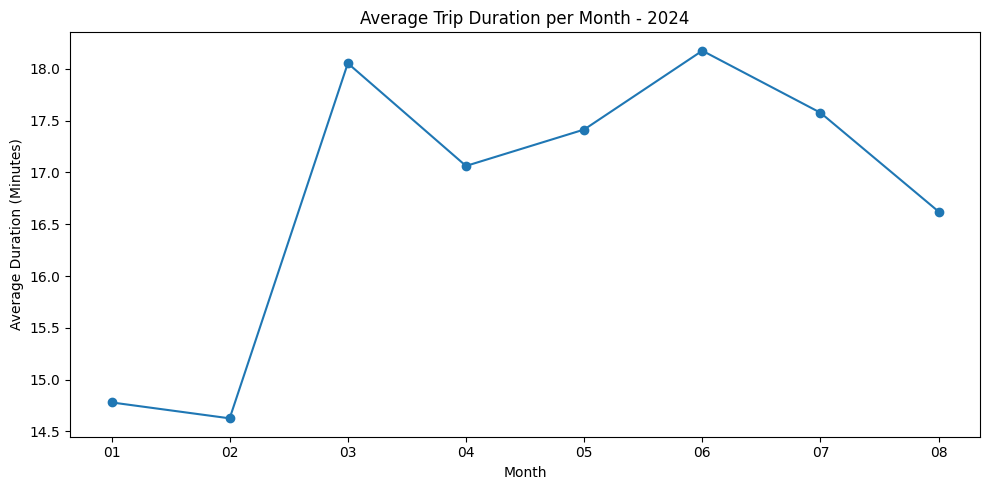

In [19]:
df = run("""SELECT COUNT(ride_id) AS total_trips,
AVG((julianday(ended_at) - julianday(started_at)) * 24 * 60) AS avg_trip_duration,
strftime('%m', started_at) AS month
FROM daily_rent_detail
WHERE started_at >= '2024-01-01'
AND started_at < '2025-01-01'
AND ended_at > started_at
GROUP BY strftime('%m', started_at)
ORDER BY month""")

display(df)

# Chart 1: Bar chart for total trips per month in year 2024

plt.figure(figsize=(10, 5))
plt.bar(df["month"], df["total_trips"])
plt.title("Total Trips per Month - 2024")
plt.xlabel("Month")
plt.ylabel("Total Trips")
plt.show()

# Chart 2: Line chart for Average Trip Duration per Month in year 2024
plt.figure(figsize=(10, 5))
plt.plot(df["month"],df["avg_trip_duration"],marker="o")
plt.title("Average Trip Duration per Month - 2024")
plt.xlabel("Month")
plt.ylabel("Average Duration (Minutes)")
plt.tight_layout()
plt.show()


## The longest 10 trips (by duration) taken in July 2024 with start time, duration.

In [20]:
run("""SELECT ride_id,started_at, ended_at, cast((julianday(ended_at) - julianday(started_at))*24*60 AS INTEGER) AS "Duration In Minutes"
FROM daily_rent_detail
WHERE started_at LIKE '2024-07%'
ORDER BY "Duration In Minutes" DESC
LIMIT 10""")

,ride_id,started_at,ended_at,Duration In Minutes
0,EE1BCA5F1D81AAB2,2024-07-23 09:54:43.562,2024-07-24 10:54:39.635,1499
1,F95C062EC5BA5D8A,2024-07-21 12:50:15.911,2024-07-22 13:50:11.171,1499
2,FF70D840F9269C80,2024-07-04 21:54:57.764,2024-07-05 22:54:37.079,1499
3,BF4DF215A31CF7AA,2024-07-26 19:08:38.083,2024-07-27 20:08:31.741,1499
4,F4789DDBB3DD0952,2024-07-08 10:11:01.609,2024-07-09 11:10:57.932,1499
5,C908D9CE0503B91F,2024-07-26 21:52:33.966,2024-07-27 22:52:28.168,1499
6,F46DCA4A2B4B78E2,2024-07-07 12:56:24.738,2024-07-08 13:56:21.002,1499
7,3AD6C6F7371760C7,2024-07-18 10:05:57.485,2024-07-19 11:05:52.408,1499
8,542457F72918517B,2024-07-21 16:10:21.882,2024-07-22 17:10:01.260,1499
9,9DB8FBE7973131E2,2024-07-05 15:17:10.679,2024-07-06 16:16:49.036,1499


## How many trips start and end at the same station (round trips)? What share of all trips is that, and how long do they last on average?

In [21]:
#Round trips: count and average duration
run("""SELECT COUNT(*) AS round_trips,
ROUND(AVG( (strftime('%s', ended_at) - strftime('%s', started_at)) / 60.0 ), 2) AS avg_duration_minutes
FROM daily_rent_detail
WHERE start_station_id = end_station_id
AND start_station_id IS NOT NULL""")

,round_trips,avg_duration_minutes
0,895823,42.37


In [22]:
# Total trips, to calculate the % share
run("""SELECT COUNT(*) AS total_trips
FROM daily_rent_detail""")

,total_trips
0,16086672


In [23]:

run("""SELECT COUNT(CASE WHEN start_station_id = end_station_id THEN 1 END) AS round_trips,
COUNT(*) AS total_trips,
ROUND(100.0 * COUNT(CASE WHEN start_station_id = end_station_id THEN 1 END) / COUNT(*), 2) AS round_trip_percentage
FROM daily_rent_detail""")

,round_trips,total_trips,round_trip_percentage
0,895823,16086672,5.57


## Which 10 stations have the most departures? Show station name, and number of trips started there.


In [24]:
run("""SELECT station_list.station_name,
COUNT(daily_rent_detail.start_station_id) AS trip_count
FROM daily_rent_detail
JOIN station_list
ON daily_rent_detail.start_station_id = station_list.station_id
GROUP BY station_list.station_name
ORDER BY trip_count DESC
LIMIT 10""")

,station_name,trip_count
0,New Hampshire Ave & T St NW,153658
1,Columbus Circle / Union Station,147372
2,15th & P St NW,140833
3,Lincoln Memorial,138744
4,1st & M St NE,130461
5,Jefferson Dr & 14th St SW,125813
6,4th St & Madison Dr NW,120612
7,14th & V St NW,117203
8,5th & K St NW,114324
9,Eastern Market Metro / Pennsylvania Ave & 8th ...,113320


## What are the 10 most popular routes (start station -> end station, excluding round trips)? Join stations twice with aliases.

In [25]:
run("""SELECT s_start.station_name AS start_station,
s_end.station_name   AS end_station,
COUNT(*) AS num_trips
FROM daily_rent_detail AS t
JOIN station_list AS s_start ON t.start_station_id = s_start.station_id
JOIN station_list AS s_end   ON t.end_station_id   = s_end.station_id
WHERE t.start_station_id != t.end_station_id
GROUP BY s_start.station_name, s_end.station_name
ORDER BY num_trips DESC
LIMIT 10""")

,start_station,end_station,num_trips
0,Columbus Circle / Union Station,8th & F St NE,9603
1,Lincoln Memorial,Jefferson Memorial,8941
2,Columbus Circle / Union Station,6th & H St NE,8697
3,8th & F St NE,Columbus Circle / Union Station,8206
4,Lincoln Memorial,Jefferson Dr & 14th St SW,8196
5,Jefferson Dr & 14th St SW,Lincoln Memorial,8177
6,Smithsonian-National Mall / Jefferson Dr & 12t...,Lincoln Memorial,7511
7,1st & M St NE,New Jersey Ave & F St NW,6799
8,Lincoln Memorial,Smithsonian-National Mall / Jefferson Dr & 12t...,6610
9,6th & H St NE,Columbus Circle / Union Station,6578


## Bucket trips into 'Short' (< 10 min), 'Medium' (10-30 min) and 'Long' (> 30 min) and show, for each bucket, the number of trips and the share taken by Members.


In [26]:
run("""SELECT CASE WHEN (julianday(ended_at) - julianday(started_at))*24*60 < 10 THEN 'Short'
WHEN (julianday(ended_at) - julianday(started_at))*24*60 BETWEEN 10 AND 30 THEN 'Medium'
ELSE 'Long'
END AS trip_duration_bucket,
COUNT(*) AS number_of_trips,
SUM(CASE WHEN member_casual = 'member' THEN 1 ELSE 0 END) * 100 / COUNT(*) AS member_share_percent
FROM daily_rent_detail
GROUP BY trip_duration_bucket""")

,trip_duration_bucket,number_of_trips,member_share_percent
0,Long,2134253,27
1,Medium,6886934,58
2,Short,7065485,73


## Trips per day of week: which weekday is the busiest and which is the quietest?

,Day,Number_of_Trips
0,Saturday,2600173
1,Friday,2323468
2,Thursday,2297670
3,Wednesday,2286858
4,Tuesday,2254723
5,Sunday,2251798
6,Monday,2071841


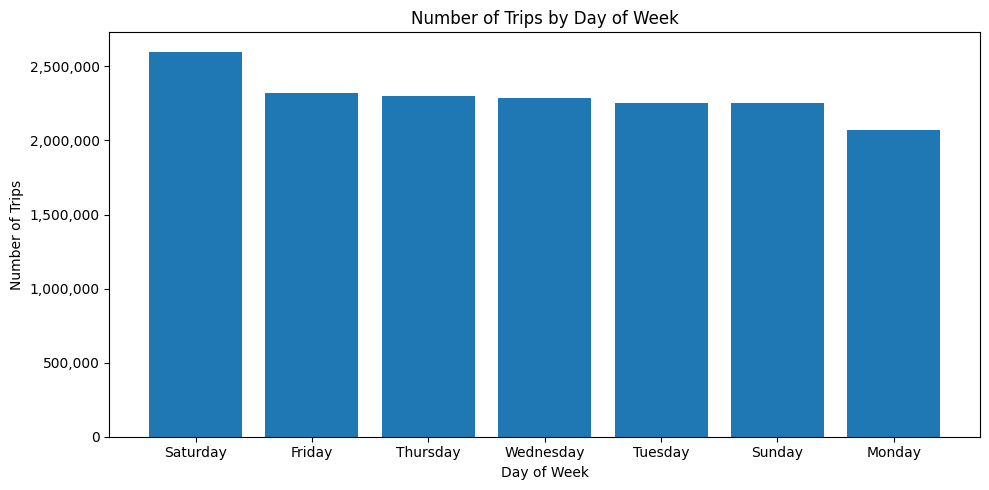

In [27]:
df_days= run("""SELECT CASE strftime('%w', started_at)
WHEN '0' THEN 'Sunday'
WHEN '1' THEN 'Monday'
WHEN '2' THEN 'Tuesday'
WHEN '3' THEN 'Wednesday'
 WHEN '4' THEN 'Thursday'
 WHEN '5' THEN 'Friday'
WHEN '6' THEN 'Saturday'
END AS Day,
COUNT(DISTINCT ride_id) AS Number_of_Trips
FROM daily_rent_detail
GROUP BY Day
ORDER BY Number_of_Trips DESC""")
display(df_days)

# After analysis: The busiest day is Saturday, while the quietest day is Monday.


# Creating bar chart for the number of Trips by Day of Week

plt.figure(figsize=(10, 5))

plt.bar(df_days["Day"], df_days["Number_of_Trips"])

plt.title("Number of Trips by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")

# Display full numbers with thousands separators
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

## At which hour of the day do most trips start? Show trips per hour (0-23). (Hint: strftime('%H', start_time).)

,hour_of_day,number_of_trips
0,00,177983
1,01,108248
2,02,66538
3,03,36504
4,04,33343
5,05,90703
6,06,258231
7,07,562829
8,08,937875
9,09,766566


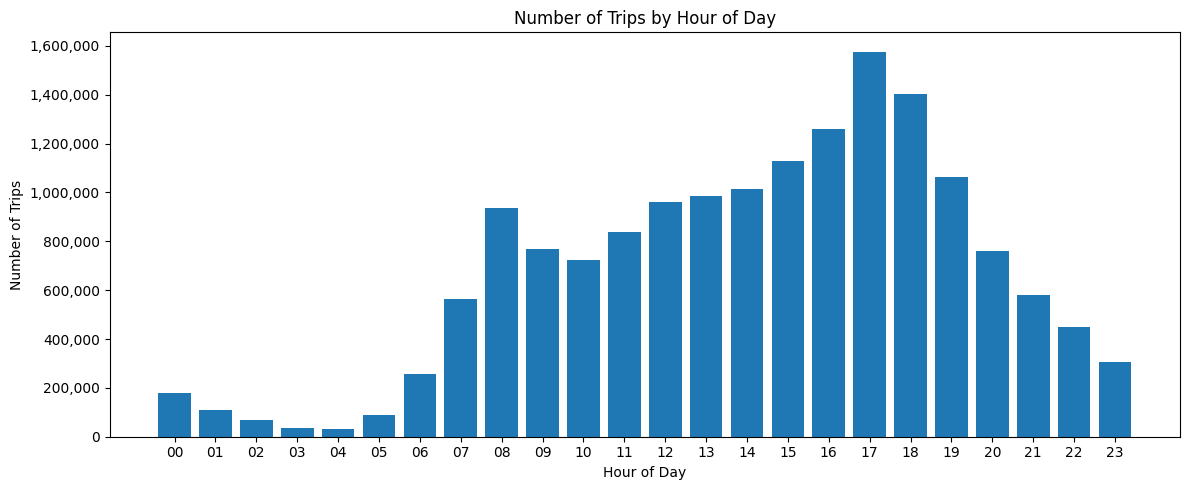

In [28]:
df_hours = run("""SELECT strftime('%H', started_at) AS hour_of_day,
COUNT(*) AS number_of_trips
FROM daily_rent_detail
GROUP BY hour_of_day
ORDER BY hour_of_day""")

display(df_hours)

# Graph: Number of Trips by Hour of Day

plt.figure(figsize=(12, 5))

plt.bar(df_hours["hour_of_day"], df_hours["number_of_trips"])

plt.title("Number of Trips by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")

plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()


## How many rainy days were there and what was the wettest day?

In [29]:
#How many rainy days were there in 2024?
run("""SELECT COUNT(*) AS rainy_days
FROM weather
WHERE precip > 0""")


,rainy_days
0,629


In [30]:
# What was the wettest day?
run("""SELECT datetime, precip
FROM weather
ORDER BY precip DESC
LIMIT 1""")


,datetime,precip
0,2020-09-10,68.131


## Does weather matter? Average trips per day for Sunny, Cloudy, Windy and Rainy days?

In [31]:
run("""SELECT w.conditions, AVG(daily_trips) AS "Average Trips Per Day"
FROM (SELECT DATE(started_at) AS ride_date, COUNT(*) AS daily_trips
FROM daily_rent_detail
GROUP BY ride_date) sq
JOIN weather w
ON sq.ride_date = w.datetime
GROUP BY w.conditions
ORDER BY "Average Trips Per Day" DESC""")

,conditions,Average Trips Per Day
0,Partially cloudy,10986.778571
1,Clear,10578.897436
2,"Rain, Partially cloudy",10499.937343
3,Overcast,7742.432432
4,"Rain, Overcast",7571.138298
5,"Rain, Freezing Drizzle/Freezing Rain, Partiall...",7155.000000
6,"Rain, Freezing Drizzle/Freezing Rain, Overcast",5282.000000
7,"Snow, Rain, Partially cloudy",3617.000000
8,"Rain, Ice, Overcast",3430.000000
9,"Snow, Partially cloudy",3345.000000


# 5. Conclusion & Business Recommendations

## 5.1. Key Findings

This collaborative project analyzed approximately 16.09 million bike-sharing trips from May 2020 to August 2024, using SQL, SQLite, Python, and Pandas to identify usage patterns and actionable business insights, with a focused monthly trend analysis covering January–August 2024.

- **User Behavior:** Registered members accounted for approximately 60.8% of trips, while casual riders had a significantly longer average trip duration (39.3 vs. 14.5 minutes).
- **Bike Preferences:** Classic bikes were the most frequently used, recording approximately 9.61 million trips.
- **Peak Demand:** 5:00 PM was the busiest starting hour, while Saturday recorded the highest trip volume by day of the week.
- **Station Activity:** Demand was concentrated at specific stations and routes, highlighting opportunities for better bike redistribution and capacity planning.
- **Trip Duration:** Short trips (under 10 minutes) represented the largest duration category, with approximately 7.07 million trips.
- **Weather Patterns:** Trip volumes varied across recorded weather conditions, suggesting that weather may be a useful factor in demand forecasting.

## 5.2. Business Recommendations

Based on these findings, the following actions could improve operational efficiency and customer experience:

1. **Optimize bike distribution** by prioritizing high-demand stations and peak hours.
2. **Improve customer retention** through commuter-focused membership benefits and targeted offers for casual riders.
3. **Plan fleet allocation** according to demand by bike type, station, and time of day.
4. **Develop demand forecasting models** using historical trips, seasonality, and weather data.
5. **Improve data quality** by validating timestamps, investigating unusually long trips, and handling missing values.

## 5.3. Final Conclusion

The analysis demonstrates how trip data can reveal meaningful patterns in rider behavior, bike preferences, and operational demand. The findings highlight opportunities to improve bike availability, optimize resource allocation, and develop more targeted customer strategies.

**Ultimately, understanding who rides, when and where demand occurs, and how usage patterns differ can help transform raw data into actionable decisions that improve service efficiency and customer satisfaction.**

